# 03 — Insights por plataforma

Os métodos do notebook 02 rodam **dentro de cada plataforma** (Instagram, TikTok, YouTube, Bilibili, RedNote).
O "top 10%" é recalculado por plataforma, porque um post top no TikTok é comparado com outros posts do TikTok.

1. Painel-resumo por plataforma
2. Formato × categoria × audiência: o que muda entre plataformas?
3. Raio-X de cada plataforma (atributos, combinações, modelo, clusters, audiência, comentários)
4. Validação: um efeito plantado **só no TikTok** aparece só no TikTok?

In [1]:
# Setup: make solution/src importable and load the posts with derived features.
import sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "solution" / "src").exists())
sys.path.insert(0, str(ROOT / "solution" / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from social_insights import data, top_performers as tp, clustering as cl, drivers as dr, audience as au, nlp, validation as va, plots

plots.apply_style()
pd.set_option("display.float_format", "{:.4f}".format)
df = data.load_posts(ROOT)
print(f"{len(df):,} posts")

52,214 posts


In [2]:
CONTENT_NO_PLATFORM = [f for f in data.FEATURES if f != "platform"]
df["sentiment"] = nlp.sentiment(df["comments_text"])
BY_PLATFORM = {p: df[df.platform == p].reset_index(drop=True) for p in data.PLATFORMS}

## 1. Painel-resumo por plataforma

In [3]:
def platform_summary(name: str, sub: pd.DataFrame) -> dict:
    row = {"plataforma": name, "posts": len(sub), "% patrocinado": sub.is_sponsored.mean() * 100}
    row |= {f"média {m}": sub[m].mean() for m in data.METRICS}
    for m in data.METRICS:
        top = tp.flag_top(sub, m)
        lifts = tp.lift_table(sub, top, CONTENT_NO_PLATFORM)
        row[f"achados FDR ({m})"] = int(lifts.significant.sum())
        row[f"AUC ({m})"] = dr.cv_top_classifier(sub, top, CONTENT_NO_PLATFORM)
    row["ganho silhueta (k=4)"] = cl.structure_test(cl.attribute_space(sub, CONTENT_NO_PLATFORM), range(4, 5))["gain"].iloc[0]
    row["p sentimento (top views vs. demais)"] = nlp.compare_sentiment(sub["sentiment"], tp.flag_top(sub, "views"))["p_value"]
    return row

summary = pd.DataFrame([platform_summary(p, s) for p, s in BY_PLATFORM.items()]).set_index("plataforma")
summary.T

plataforma,Instagram,TikTok,YouTube,Bilibili,RedNote
posts,10423.0000,10296.0000,10495.0000,10598.0000,10402.0000
% patrocinado,41.9169,43.1333,43.1634,42.0174,43.4628
média views,10100.3491,10100.5911,10099.7792,10099.9291,10100.7822
média likes,1509.5254,1510.5664,1510.0544,1510.4132,1510.8169
média shares,300.1712,299.8662,300.1404,300.0924,299.8177
média comments_count,199.9888,199.9986,199.8358,200.0405,200.2146
achados FDR (views),0.0000,0.0000,0.0000,0.0000,0.0000
AUC (views),0.5224,0.4785,0.5215,0.5244,0.4980
achados FDR (likes),0.0000,0.0000,0.0000,0.0000,0.0000
AUC (likes),0.5116,0.5140,0.4976,0.4979,0.4893


**Leitura:** as 5 plataformas têm as mesmas médias (~10.100 views, ~1.510 likes, ~300 shares, ~200 comentários). Em nenhuma delas um atributo sobrevive ao FDR, a AUC fica ≈ 0,50 e os clusters não superam o nulo.

## 2. O que muda entre plataformas?

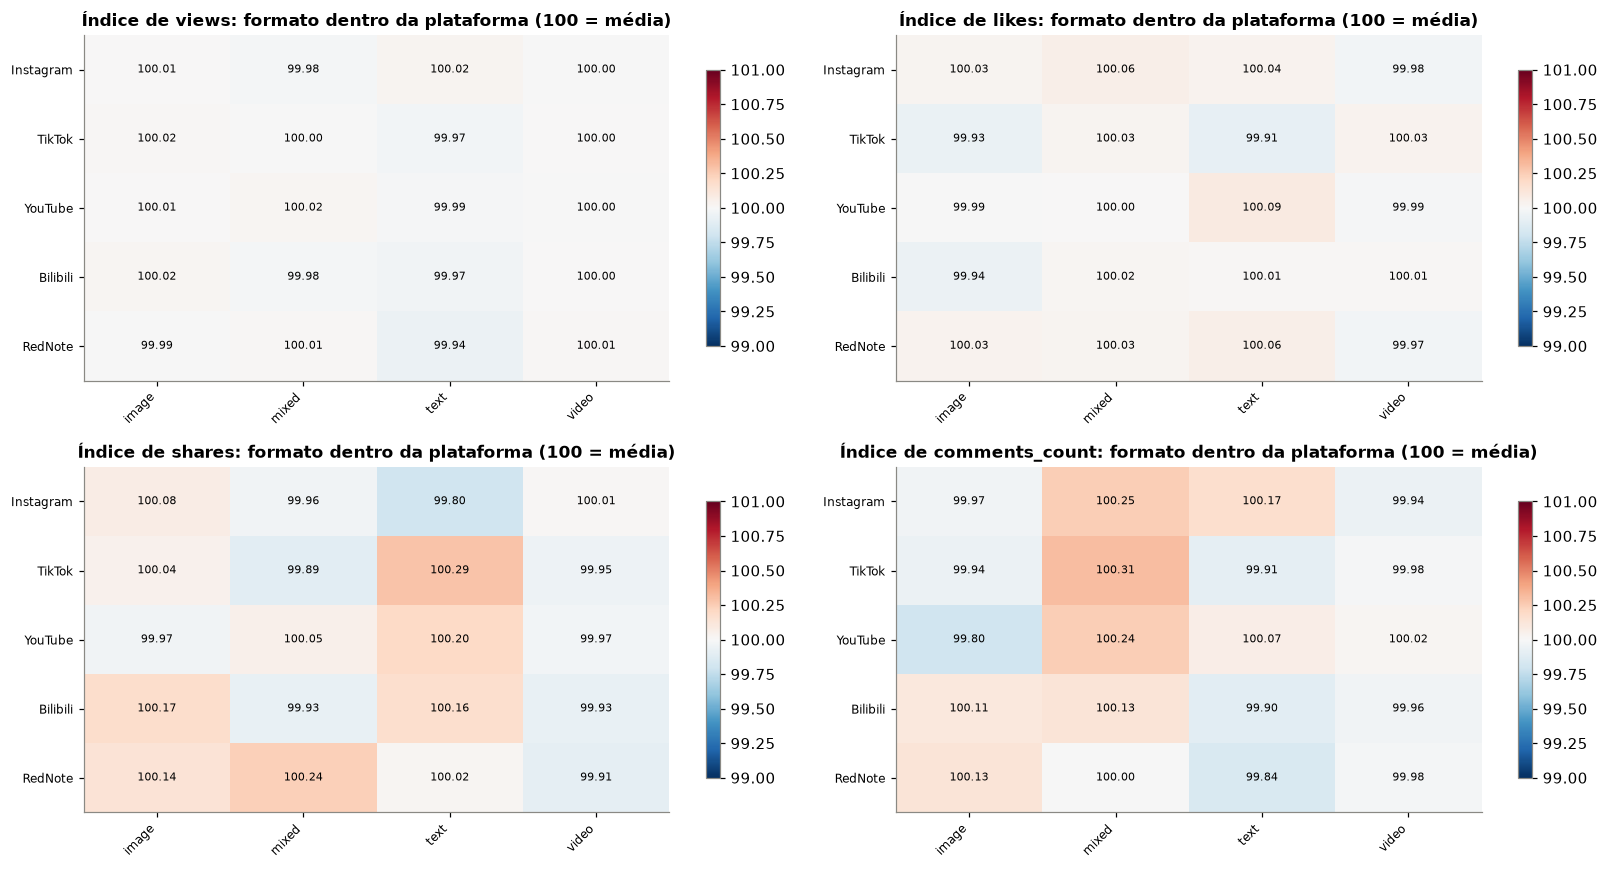

**p-value (Kruskal): o formato muda a métrica dentro da plataforma?**

,views,likes,shares,comments_count
platform,,,,
Instagram,0.7452,0.4246,0.5452,0.6651
TikTok,0.6843,0.3536,0.2781,0.6140
YouTube,0.9106,0.8012,0.6921,0.5486
Bilibili,0.3452,0.5416,0.1864,0.6169
RedNote,0.3111,0.6592,0.3355,0.7163


In [4]:
fig, axes = plt.subplots(2, 2, figsize=(15, 8))
for ax, m in zip(axes.flat, data.METRICS):
    idx = df.pivot_table(m, "platform", "content_type").div(df.groupby("platform")[m].mean(), axis=0) * 100
    plots.heatmap(ax, idx.loc[data.PLATFORMS], f"Índice de {m}: formato dentro da plataforma (100 = média)", vmin=99, vmax=101, fmt="{:.2f}")
fig.tight_layout(); plt.show()

pvals = pd.DataFrame({m: au.interaction_pvalues(df, "platform", "content_type", m) for m in data.METRICS}).loc[data.PLATFORMS]
display(Markdown("**p-value (Kruskal): o formato muda a métrica dentro da plataforma?**"))
pvals

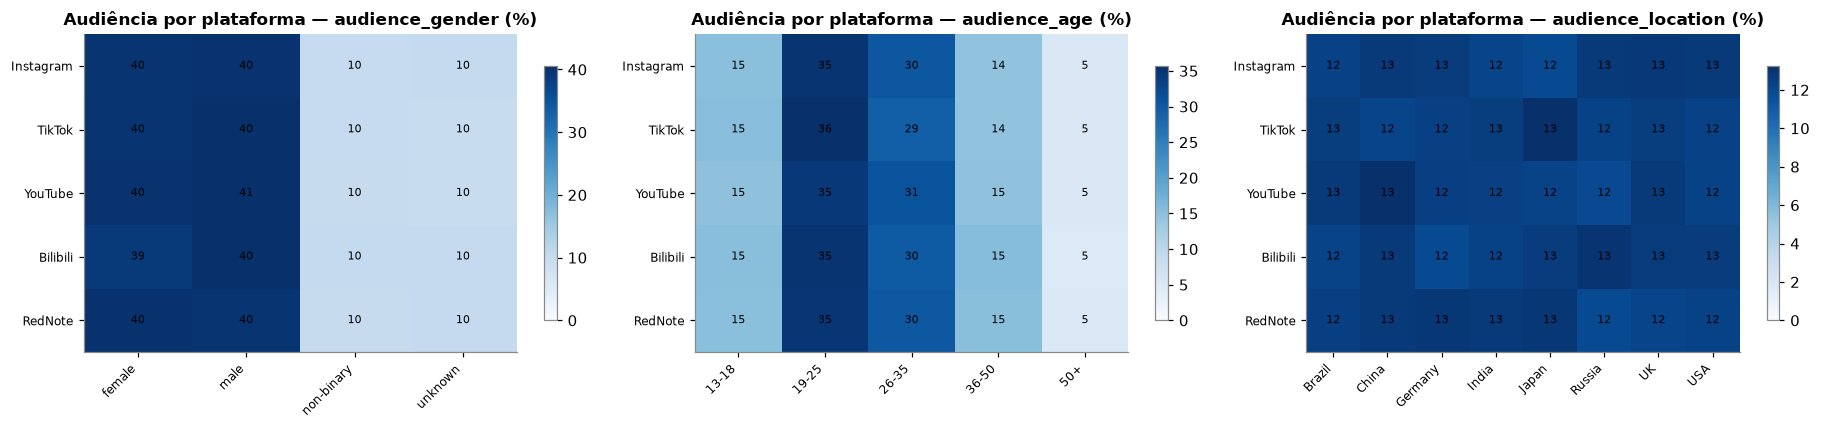

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4))
for ax, aud in zip(axes, data.AUDIENCE):
    plots.heatmap(ax, au.audience_mix(df, "platform", aud).loc[data.PLATFORMS] * 100,
                  f"Audiência por plataforma — {aud.replace('_distribution', '')} (%)", cmap="Blues", vmin=0, fmt="{:.0f}")
fig.tight_layout(); plt.show()

In [6]:
# Audience × content type inside each platform: any cell clearly over/under-represented?
rows = []
for p, sub in BY_PLATFORM.items():
    for by in ["content_type", "content_category", "is_sponsored"]:
        for aud in data.AUDIENCE:
            _, v, pval = au.adjusted_residuals(sub, by, aud)
            rows.append({"plataforma": p, "conteúdo": by, "audiência": aud, "cramers_v": v, "p_value": pval})
aud_tests = pd.DataFrame(rows)
aud_tests["significativo (Bonferroni)"] = aud_tests.p_value < 0.05 / len(aud_tests)
display(aud_tests.sort_values("cramers_v", ascending=False).head(10))
print("Associações significativas:", int(aud_tests["significativo (Bonferroni)"].sum()), "de", len(aud_tests))

,plataforma,conteúdo,audiência,cramers_v,p_value,significativo (Bonferroni)
5,Instagram,content_category,audience_location,0.0375,0.0095,False
35,Bilibili,is_sponsored,audience_location,0.0307,0.1874,False
14,TikTok,content_category,audience_location,0.0294,0.2152,False
11,TikTok,content_type,audience_location,0.0292,0.1937,False
23,YouTube,content_category,audience_location,0.0292,0.2128,False
16,TikTok,is_sponsored,audience_age_distribution,0.0284,0.0809,False
3,Instagram,content_category,audience_gender_distribution,0.0266,0.0221,False
32,Bilibili,content_category,audience_location,0.0258,0.4415,False
20,YouTube,content_type,audience_location,0.0246,0.5862,False
37,RedNote,content_type,audience_age_distribution,0.0244,0.1003,False


Associações significativas: 0 de 45


## 3. Raio-X por plataforma

### Instagram  ·  10,423 posts

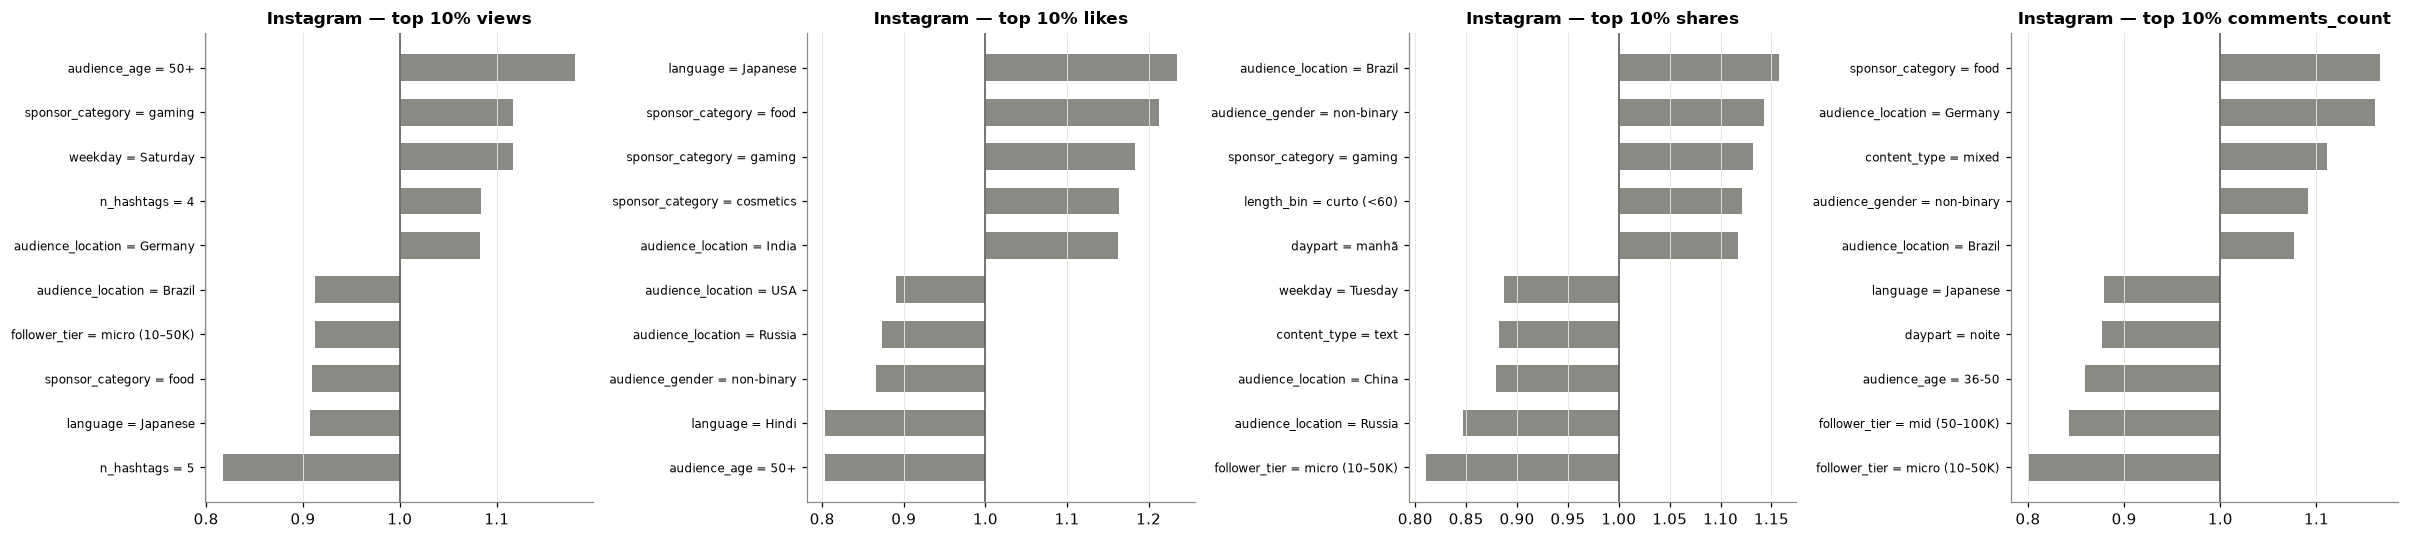

,regras,"p<0,05",esperado por acaso,FDR,melhor regra (aparente),lift,q
views,1154,45,57.7000,0,content_category & audience_age_distribution =...,1.5928,1.0000
likes,1154,70,57.7000,0,n_hashtags & audience_location = 4 & Brazil,1.5756,0.7072
shares,1154,47,57.7000,0,n_hashtags & audience_location = 0 & Brazil,1.4590,0.9981
comments_count,1154,46,57.7000,0,n_hashtags & audience_location = 5 & Germany,1.5779,1.0000


### TikTok  ·  10,296 posts

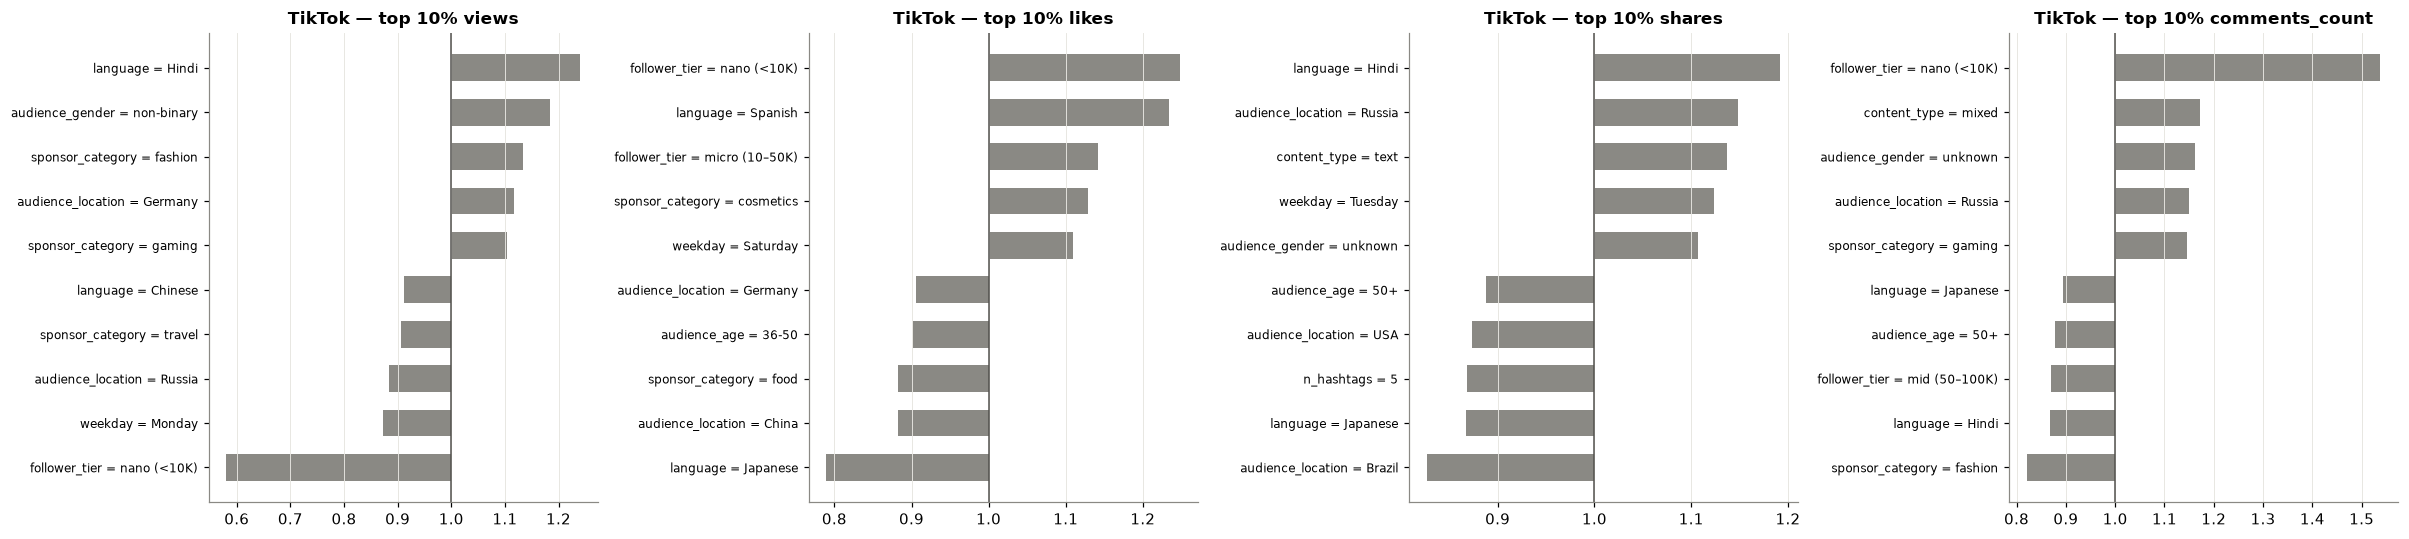

,regras,"p<0,05",esperado por acaso,FDR,melhor regra (aparente),lift,q
views,1149,51,57.4000,0,language & daypart = Hindi & noite,1.6163,0.2654
likes,1149,49,57.4000,2,language & daypart = Hindi & manhã,1.6868,0.1035
shares,1149,59,57.4000,0,n_hashtags & audience_location = 0 & Russia,1.6201,0.8524
comments_count,1149,47,57.4000,0,content_type & length_bin = mixed & longo (180...,1.5799,0.7879


### YouTube  ·  10,495 posts

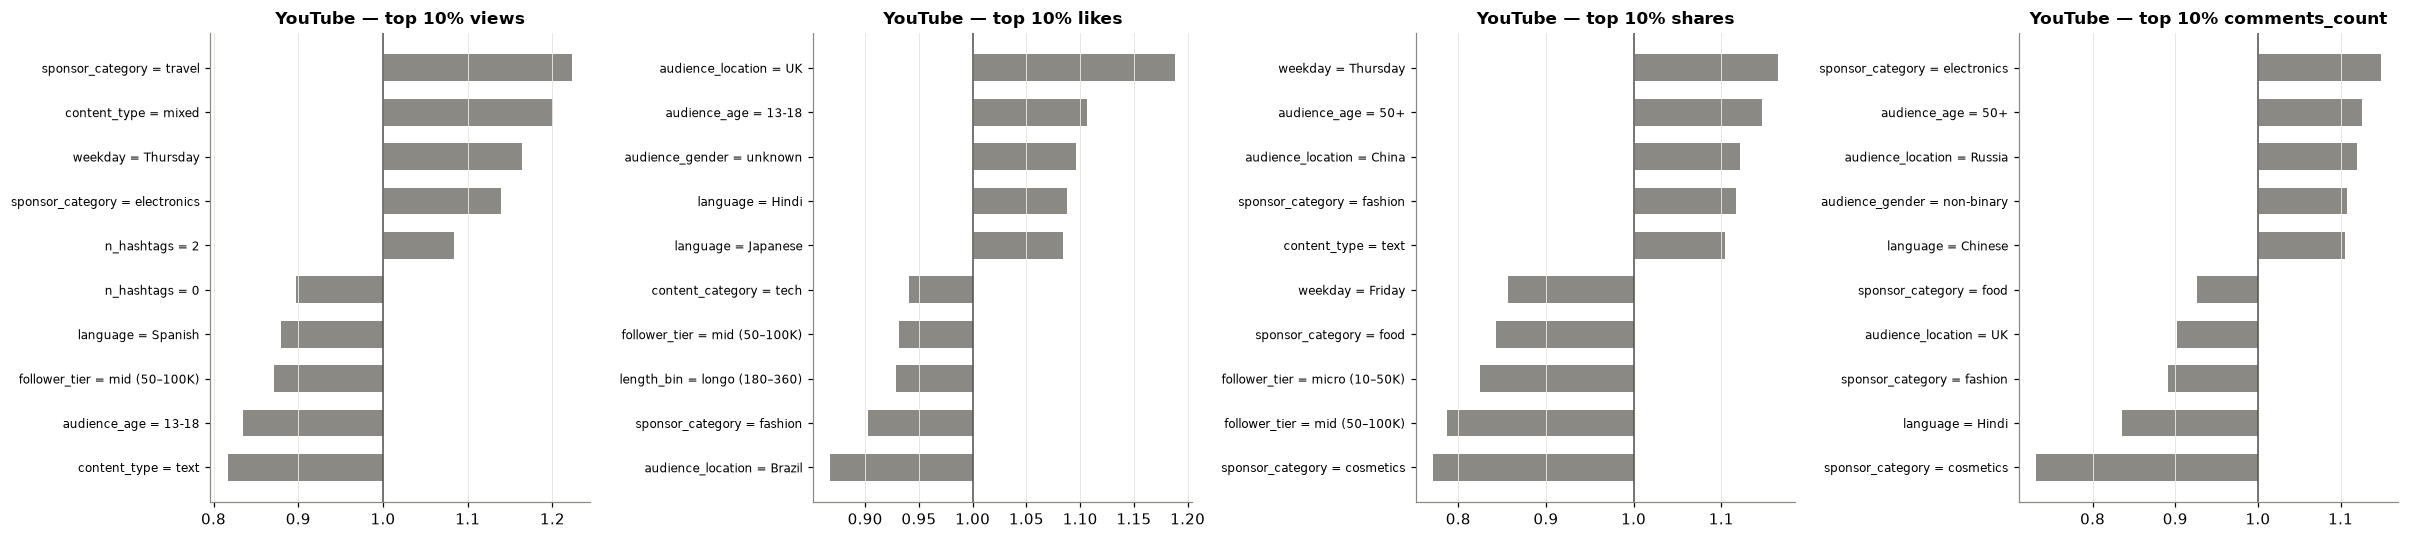

,regras,"p<0,05",esperado por acaso,FDR,melhor regra (aparente),lift,q
views,1162,55,58.1000,0,content_type & content_category = mixed & tech,1.5882,0.5706
likes,1162,26,58.1000,0,content_type & daypart = text & manhã,1.5304,1.0000
shares,1162,48,58.1000,0,n_hashtags & weekday = 5 & Thursday,1.4533,1.0000
comments_count,1162,31,58.1000,0,daypart & audience_gender_distribution = noite...,1.4778,1.0000


### Bilibili  ·  10,598 posts

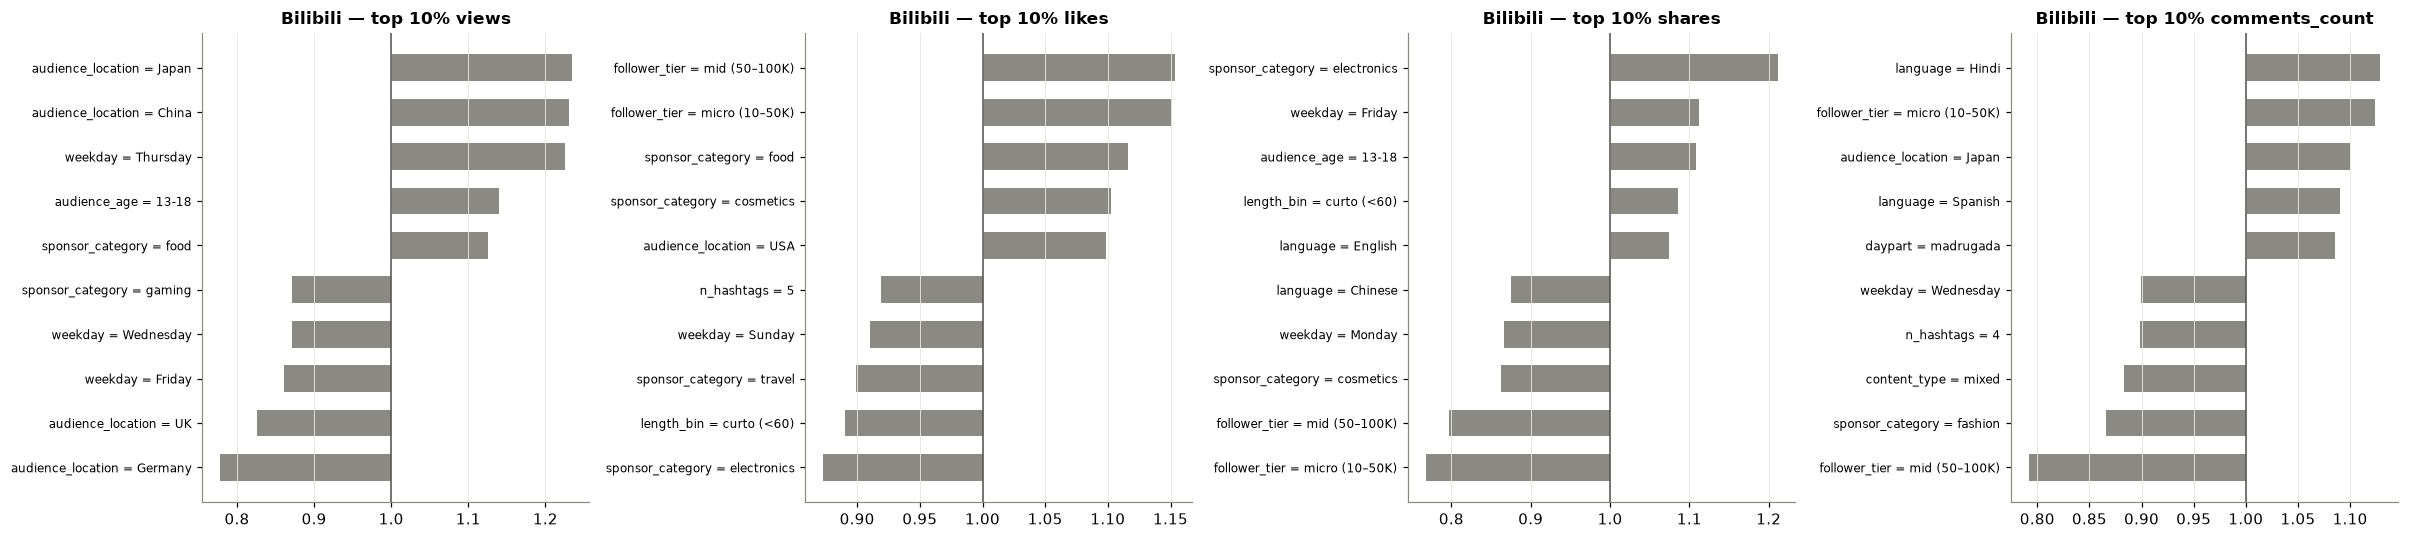

,regras,"p<0,05",esperado por acaso,FDR,melhor regra (aparente),lift,q
views,1175,83,58.8000,0,weekday & audience_location = Thursday & Japan,1.5929,0.3729
likes,1175,36,58.8000,0,n_hashtags & audience_location = 2 & USA,1.5328,1.0000
shares,1175,36,58.8000,1,n_hashtags & weekday = 4 & Friday,1.7715,0.0315
comments_count,1175,32,58.8000,0,language & length_bin = Japanese & longo (180–...,1.5123,1.0000


### RedNote  ·  10,402 posts

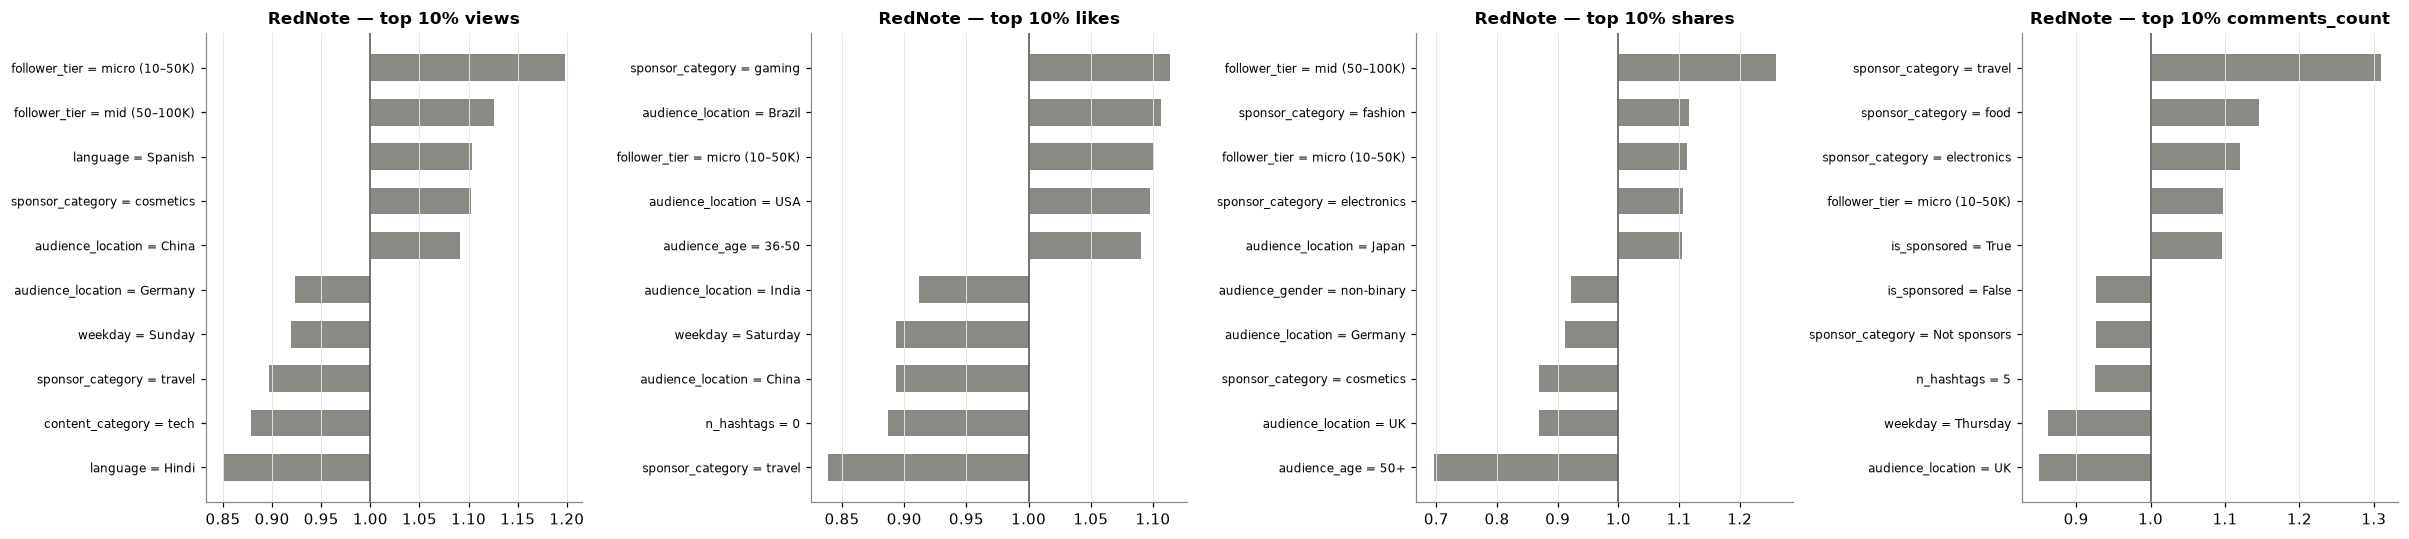

,regras,"p<0,05",esperado por acaso,FDR,melhor regra (aparente),lift,q
views,1162,38,58.1000,0,content_type & weekday = image & Sunday,1.5840,0.7645
likes,1162,26,58.1000,0,content_type & audience_location = image & USA,1.5219,1.0000
shares,1162,34,58.1000,0,audience_age_distribution & audience_location ...,1.5452,1.0000
comments_count,1162,58,58.1000,0,length_bin & sponsor_category = médio (60–180)...,1.5748,0.5749


In [7]:
ALL_RULES = []

def platform_xray(name: str, sub: pd.DataFrame) -> None:
    display(Markdown(f"### {name}  ·  {len(sub):,} posts"))
    fig, axes = plt.subplots(1, 4, figsize=(22, 5))
    rules = {}
    for ax, m in zip(axes, data.METRICS):
        top = tp.flag_top(sub, m)
        plots.lift_bars(ax, tp.lift_table(sub, top, CONTENT_NO_PLATFORM), f"{name} — top 10% {m}", n=10)
        pairs = tp.pair_lift_table(sub, top, CONTENT_NO_PLATFORM)
        ALL_RULES.append(pairs.assign(plataforma=name, métrica=m))
        rules[m] = {"regras": len(pairs), "p<0,05": int((pairs.p_value < 0.05).sum()),
                    "esperado por acaso": tp.expected_false_positives(pairs), "FDR": int(pairs.significant.sum()),
                    "melhor regra (aparente)": pairs.iloc[0]["feature"] + " = " + pairs.iloc[0]["value"], "lift": pairs.iloc[0]["lift"], "q": pairs.iloc[0]["q_value"]}
    fig.tight_layout(); plt.show()
    display(pd.DataFrame(rules).T)

for name, sub in BY_PLATFORM.items():
    platform_xray(name, sub)

**Leitura:** em cada plataforma, a "melhor regra aparente" tem lift de 1,5–1,8x, e o número de p < 0,05 bate com o esperado por acaso.
Um relatório sem correção daria 5 estratégias diferentes (uma por plataforma), todas baseadas em ruído.

### 3.1 Os poucos "achados" sobrevivem a uma correção global?
O FDR acima foi aplicado em cada tabela (plataforma × métrica). São 20 tabelas, e com 20 famílias 1–2 falsos achados são esperados.
A pergunta certa é: corrigindo **todos os ~23 mil testes juntos**, sobra algo?

In [8]:
from statsmodels.stats.multitest import multipletests

rules = pd.concat(ALL_RULES, ignore_index=True)
rules["q_global"] = multipletests(rules["p_value"], method="fdr_bh")[1]
display(Markdown(f"Testes: **{len(rules):,}** · significativos por tabela: **{int(rules.significant.sum())}** · "
                 f"significativos na correção global: **{int((rules.q_global < tp.ALPHA).sum())}**"))
rules[rules.significant][["plataforma", "métrica", "feature", "value", "n", "lift", "p_value", "q_value", "q_global"]]

Testes: **23,208** · significativos por tabela: **3** · significativos na correção global: **0**

,plataforma,métrica,feature,value,n,lift,p_value,q_value,q_global
5769,TikTok,likes,content_category & language,beauty & Spanish,451,1.5570,0.0001,0.0400,0.5389
5770,TikTok,likes,content_type & language,video & Spanish,625,1.5350,0.0000,0.0059,0.1187
16210,Bilibili,shares,n_hashtags & weekday,4 & Friday,253,1.7715,0.0000,0.0315,0.3113


**Leitura:** 3 regras passaram por tabela: espanhol + beleza e espanhol + vídeo → likes no TikTok (são quase os mesmos posts), e 4 hashtags + sexta → shares no Bilibili.
"Vídeo em espanhol no TikTok" até parece plausível, e é aí que mora o perigo. **Nenhuma passa pela correção global** (q ≥ 0,12), e nenhuma se repete em outra métrica ou plataforma. Isso é típico de falso positivo.
**Regra para o time:** um achado só vira ação se (1) sobreviver à correção global, (2) fizer sentido de negócio e (3) se repetir num teste A/B.

## 4. Validação: efeito plantado só no TikTok

In [9]:
planted = va.demo_segment(df)  # TikTok × video × tech
injected = va.inject_uplift(df, planted, "views", uplift=0.02)
rows = []
for p in data.PLATFORMS:
    sub = injected[injected.platform == p].reset_index(drop=True)
    top = tp.flag_top(sub, "views")
    lifts = tp.lift_table(sub, top, CONTENT_NO_PLATFORM)
    best = tp.summarize_significant(lifts, 1)
    rows.append({"plataforma": p, "achados FDR": int(lifts.significant.sum()),
                 "principal achado": (best.feature + " = " + best.value).iloc[0] if len(best) else "—",
                 "AUC": dr.cv_top_classifier(sub, top, CONTENT_NO_PLATFORM)})
pd.DataFrame(rows).set_index("plataforma")

,achados FDR,principal achado,AUC
plataforma,,,
Instagram,0,—,0.5224
TikTok,10,content_category = tech,0.8074
YouTube,0,—,0.5215
Bilibili,0,—,0.5244
RedNote,0,—,0.4980


**Leitura:** o efeito plantado aparece **só no TikTok** (categoria tech e formato vídeo, AUC > 0,5). As outras plataformas continuam sem achados.
O método separa bem sinal de ruído por plataforma.

## 5. Conclusões por plataforma
1. **Nenhuma plataforma tem uma "receita" vencedora** nos dados: formato, categoria, creator, horário, patrocínio e audiência não mudam views, likes, shares ou comentários em nenhuma delas.
2. **A audiência é igual entre plataformas** (mesmo mix de gênero, idade e país). Os dados não sustentam a ideia de "TikTok = jovem".
3. **Recomendações específicas por plataforma tiradas destes dados seriam ruído.** O valor está no pipeline, validado para achar efeitos de 2% por plataforma, rodando sobre os dados reais da empresa.